# Experimentos de classificação


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
CLASSES = ("maj", "m", "dim", "7", "maj7", "m7")
FINGER_COLUMNS = tuple(f"STRING_{position}" for position in range(1, 7))


## Dados


In [2]:
ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "chord-fingers.csv").exists():
    ROOT = ROOT.parent

data = pd.read_csv(ROOT / "data" / "raw" / "chord-fingers.csv", sep=";", dtype="string")
data = data.loc[data["CHORD_TYPE"].isin(CLASSES)].drop_duplicates().copy()

# Separa as seis cordas na ordem original.
finger_positions = data["FINGER_POSITIONS"].str.split(",", expand=True)
finger_positions.columns = FINGER_COLUMNS
X = pd.concat([data[["CHORD_ROOT"]], finger_positions], axis=1).reset_index(drop=True)
y = data["CHORD_TYPE"].reset_index(drop=True)

assert X.shape == (959, 7)
assert y.nunique() == 6
print("Preditores:", X.shape, "| Alvo:", y.shape)


Preditores: (959, 7) | Alvo: (959,)


## Validação cruzada


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(cv.split(X, y))  # Mesmas partições para todos os modelos.

classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=SEED),
}
scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}


In [4]:
comparison_rows = []
class_tables = {}
confusion_matrices = {}

for name, classifier in classifiers.items():
    # O encoder é ajustado somente no treino de cada fold.
    pipeline = Pipeline([
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ("classifier", classifier),
    ])
    scores = cross_validate(
        pipeline, X, y, cv=splits, scoring=scoring, return_estimator=True, error_score="raise"
    )

    predictions = pd.Series(index=y.index, dtype="string")
    for (_, test_indices), estimator in zip(splits, scores["estimator"]):
        predictions.iloc[test_indices] = estimator.predict(X.iloc[test_indices])

    comparison_rows.append({
        "Algorithm": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision (macro)": scores["test_precision_macro"].mean(),
        "Recall (macro)": scores["test_recall_macro"].mean(),
        "F1-score (macro)": scores["test_f1_macro"].mean(),
        "Training time (s)": scores["fit_time"].mean(),
    })
    report = classification_report(
        y, predictions, labels=CLASSES, output_dict=True, zero_division=0
    )
    class_tables[name] = pd.DataFrame(report).T.loc[
        list(CLASSES), ["precision", "recall", "f1-score", "support"]
    ]
    confusion_matrices[name] = confusion_matrix(y, predictions, labels=CLASSES)


## Resultados


In [5]:
comparison = pd.DataFrame(comparison_rows).set_index("Algorithm")
comparison.round(4)


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Training time (s)
Algorithm,,,,,
Decision Tree,0.7184,0.7143,0.7078,0.7074,0.0171
KNN,0.7132,0.7324,0.7085,0.7121,0.0063
Random Forest,0.7476,0.7539,0.7369,0.7405,0.2205


In [6]:
class_metrics = pd.concat(class_tables, names=["Algorithm", "Class"])
class_metrics.round(4)


precision  recall  f1-score  support
Algorithm     Class                                      
Decision Tree maj       0.7745  0.7783    0.7764    203.0
              m         0.6957  0.7320    0.7134    153.0
              dim       0.6087  0.6512    0.6292     86.0
              7         0.6808  0.7073    0.6938    205.0
              maj7      0.7265  0.6250    0.6719    136.0
              m7        0.7733  0.7557    0.7644    176.0
KNN           maj       0.7273  0.7488    0.7379    203.0
              m         0.6748  0.7190    0.6962    153.0
              dim       0.7079  0.7326    0.7200     86.0
              7         0.6567  0.7463    0.6986    205.0
              maj7      0.8710  0.5956    0.7074    136.0
              m7        0.7267  0.7102    0.7184    176.0
Random Forest maj       0.7191  0.8325    0.7717    203.0
              m         0.7403  0.7451    0.7427    153.0
              dim       0.7342  0.6744    0.7030     86.0
              7         0.7449  0.7122    0.7282    205.0
              maj7      0.7583  0.6691    0.7109    136.0
              m7        0.7943  0.7898    0.7920    176.0

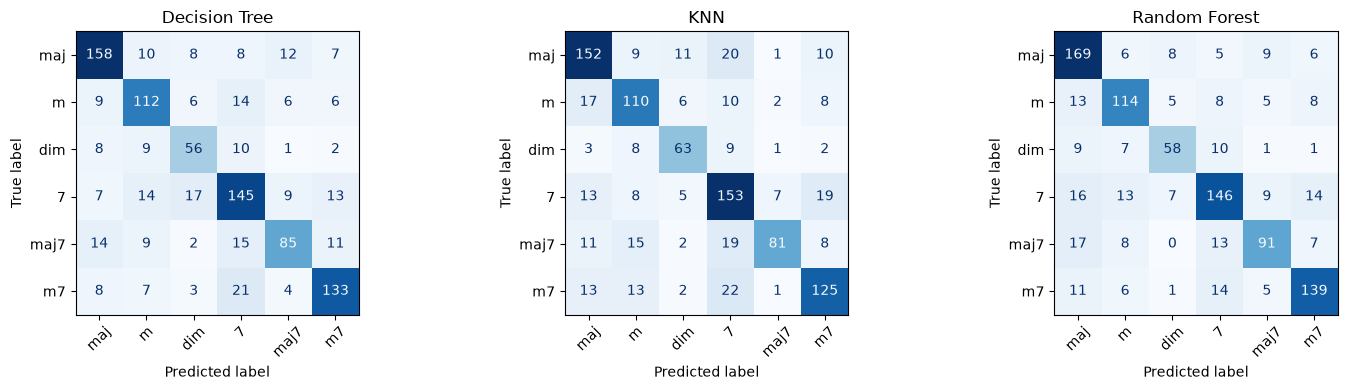

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (name, matrix) in zip(axes, confusion_matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
        ax=axis, cmap="Blues", colorbar=False
    )
    axis.set_title(name)
    axis.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
